In [1]:
import numpy as np 
from pathlib import Path
import numpy as np
import xarray as xr
from cpom.areas.area_plot import Polarplot


In [19]:


data_dir = Path("/home/willisc3/luna/CPOM/archive/SATS/LASER/PRE-ICEBRIDGE/BLATM2_Greenland/")
files = sorted(data_dir.glob("**/*.nc"))
if not files:
    raise FileNotFoundError(f"No NetCDF files found in {data_dir}")

lat, lon, height = [], [], []
for f in files:
    with xr.open_dataset(f) as ds:
        lat.append(ds["lat"].values.ravel())
        lon.append(ds["lon"].values.ravel())
        height.append(ds["height"].values.ravel())

lat, lon, height = (np.concatenate(x) for x in (lat, lon, height))

In [20]:
from pathlib import Path
import numpy as np
import xarray as xr

dd = Path("/home/willisc3/luna/CPOM/archive/SATS/RA/ENV/L2/FDR4ALT/AMPLI_TDP/greenland/land_ice/")

files_alt = sorted(dd.glob("**/*.nc"))
if not files_alt:
    raise FileNotFoundError(f"No NetCDF files found in {dd}")


def read_var(ds, name):
    """Read a variable as float, replacing fill values with NaN and applying scale/offset."""
    var = ds[name]
    data = var.values.astype("float64").ravel()
    for key in ("_FillValue", "missing_value"):
        if key in var.attrs:
            data[data == var.attrs[key]] = np.nan
    return data * var.attrs.get("scale_factor", 1) + var.attrs.get("add_offset", 0)


lat_alt, lon_alt, elevation_alt = [], [], []
for f in files_alt:
    with xr.open_dataset(
        f,
        group="expert",
        mask_and_scale=False,
        decode_times=False,
        ) as ds:
            lat_alt.append(read_var(ds, "latitude_poca_ampli"))
            lon_alt.append(read_var(ds, "longitude_poca_ampli"))
            elevation_alt.append(read_var(ds, "elevation_poca_ampli"))

lat_alt, lon_alt, elevation_alt = (np.concatenate(x) for x in (lat_alt, lon_alt, elevation_alt))

KeyboardInterrupt: 

-------------------------------------------------------------
Background: basic_land
alpha= 1.0
Loading basic_land background
-------------------------------------------------------------
loading data set 0: unnamed
-------------------------------------------------------------
Background: basic_land
alpha= 1.0
Loading basic_land background
-------------------------------------------------------------


/home/willisc3/cpom_software2/src/cpom/areas/area_plot.py:1768: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(tick_labels)


drawing coastline for main map..
Adding map scale bar
Scalebar location latlon == x,y -35 60 577060.7250919531 -3272673.999029407
Scalebar width 400


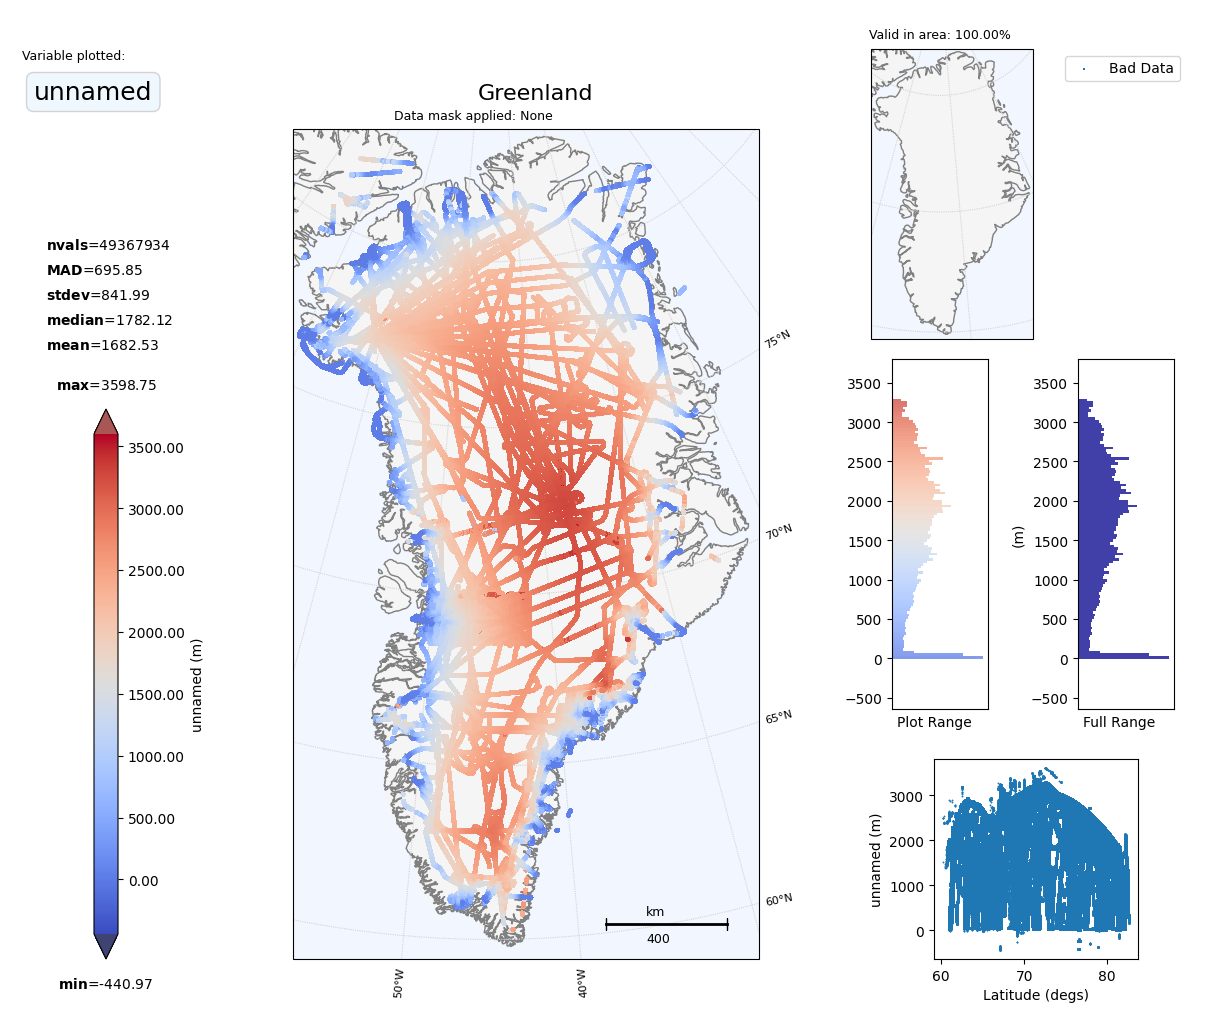

In [9]:

Polarplot("greenland").plot_points(
    {
        # "name": f"dh_{epoch_id} ({min_date} to {max_date})",
        "lats": lat,
        "lons": lon,
        "vals": height,
        # "valid_range": tuple(params.plot_range),
        "units": "m",
        "cmap_name": "coolwarm",
    },
    # output_dir=str(params.out_dir),
    # output_file=(f"{params.plotting_column}_{epoch_id}_{min_date}-{max_date}.png"),
)


In [ ]:

Polarplot("greenland").plot_points(
    {
        # "name": f"dh_{epoch_id} ({min_date} to {max_date})",
        "lats": lat_alt,
        "lons": lon_alt,
        "vals": elevation_alt,
        # "valid_range": tuple(params.plot_range),
        "units": "m",
        "cmap_name": "coolwarm",
    },
    # output_dir=str(params.out_dir),
    # output_file=(f"{params.plotting_column}_{epoch_id}_{min_date}-{max_date}.png"),
)

NameError: name 'lat_alt' is not defined

-------------------------------------------------------------
Background: basic_land
alpha= 1.0
Loading basic_land background
-------------------------------------------------------------
loading data set 0: Roemer
-------------------------------------------------------------
Background: basic_land
alpha= 1.0
Loading basic_land background
-------------------------------------------------------------


/home/willisc3/cpom_software2/src/cpom/areas/area_plot.py:1768: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(tick_labels)


drawing coastline for main map..
Adding map scale bar
Scalebar location latlon == x,y -35 60 577060.7250919531 -3272673.999029407
Scalebar width 400
Saving plot to /tmp/roemer_compare_to_icebridge.png at 85 dpi
-------------------------------------------------------------
Background: basic_land
alpha= 1.0
Loading basic_land background
-------------------------------------------------------------
loading data set 0: Ampli
-------------------------------------------------------------
Background: basic_land
alpha= 1.0
Loading basic_land background
-------------------------------------------------------------


/home/willisc3/cpom_software2/src/cpom/areas/area_plot.py:1768: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(tick_labels)


drawing coastline for main map..
Adding map scale bar
Scalebar location latlon == x,y -35 60 577060.7250919531 -3272673.999029407
Scalebar width 400
Saving plot to /tmp/ampli_compare_to_icebridge.png at 85 dpi
-------------------------------------------------------------
Background: basic_land
alpha= 1.0
Loading basic_land background
-------------------------------------------------------------
loading data set 0: TDP
-------------------------------------------------------------
Background: basic_land
alpha= 1.0
Loading basic_land background
-------------------------------------------------------------


/home/willisc3/cpom_software2/src/cpom/areas/area_plot.py:1768: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(tick_labels)


drawing coastline for main map..
Adding map scale bar
Scalebar location latlon == x,y -35 60 577060.7250919531 -3272673.999029407
Scalebar width 400
Saving plot to /tmp/tdp_compare_to_icebridge.png at 85 dpi


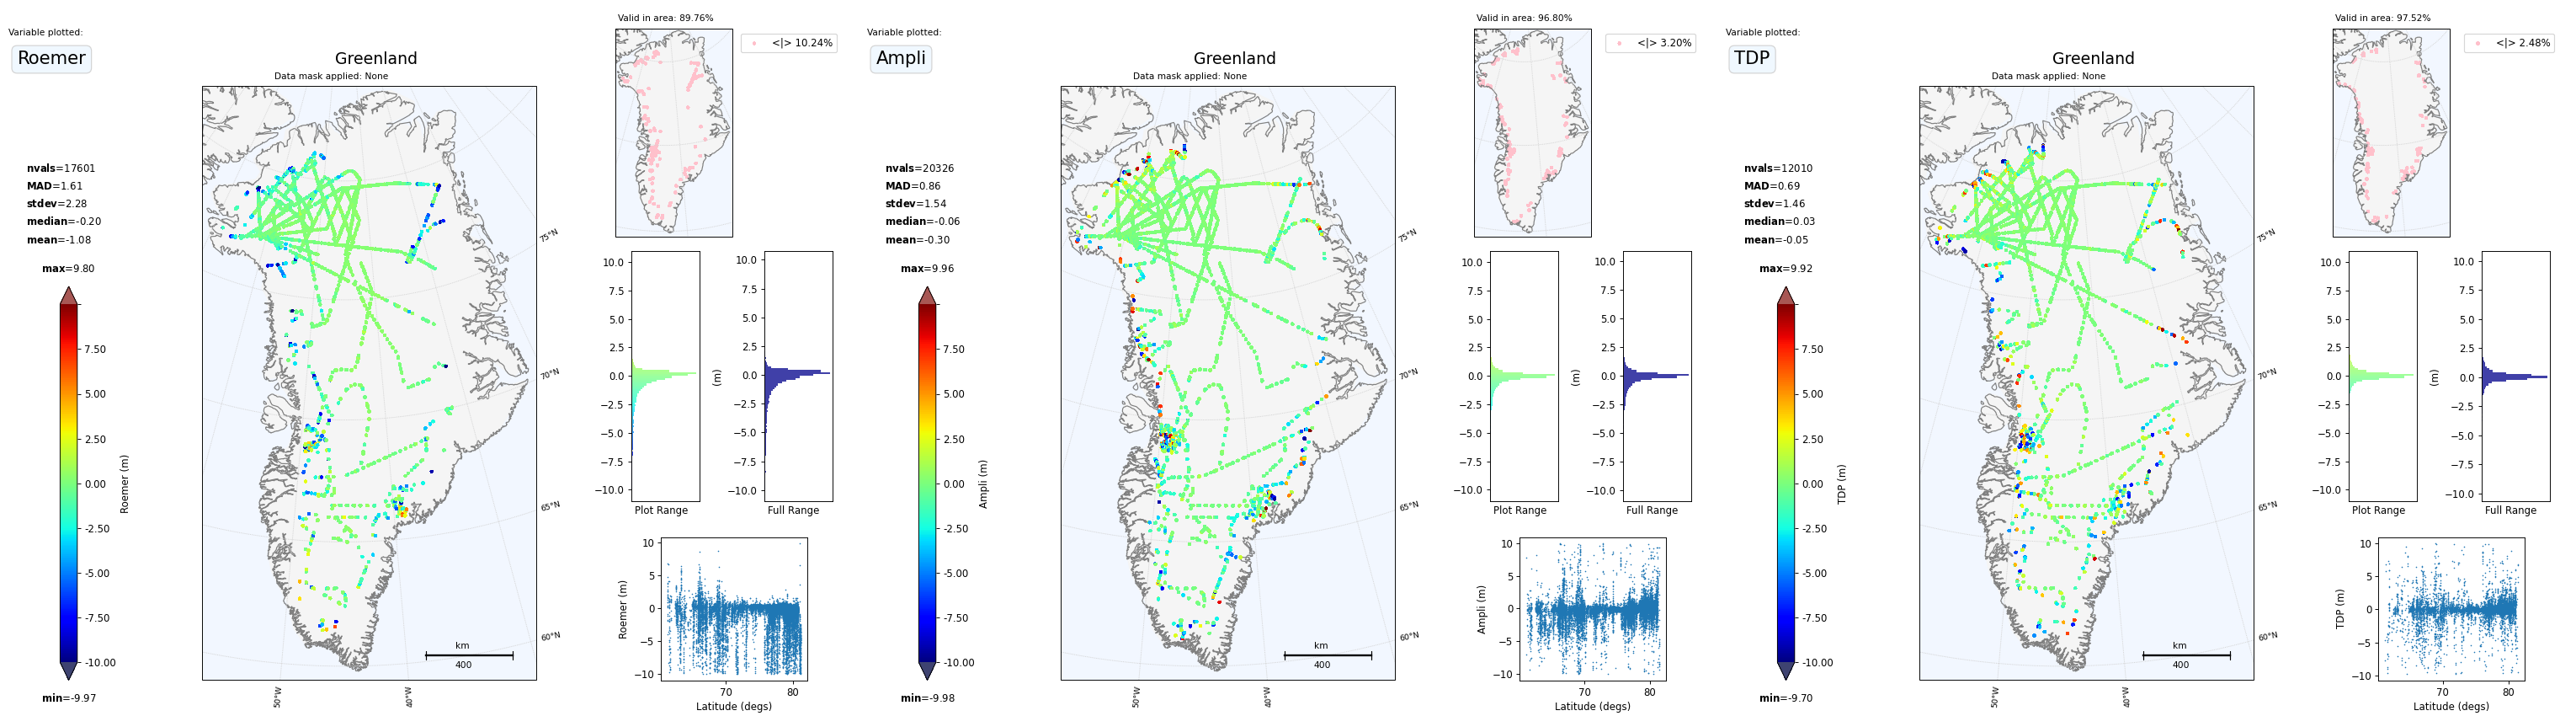

In [97]:
import os
import matplotlib.pyplot as plt
from PIL import Image

roemer = np.load("/home/willisc3/luna/CPOM/willisc3/Validation/env_roemer_vs_blatm2_500_30_nearest_v2/20030509_20070511/p2p_diffs_greenland_is.npz")
ampli = np.load("/home/willisc3/luna/CPOM/willisc3/Validation/env_ampli_vs_blatm2_500_30_nearest_v2/20030509_20070511/p2p_diffs_greenland_is.npz")
tdp = np.load("/home/willisc3/luna/CPOM/willisc3/Validation/env_tdp_vs_blatm2_500_30_nearest_v2/20030509_20070511/p2p_diffs_greenland_is.npz")
# example datasets
datasets = {
    "Roemer compare to icebridge": {
        "lats": roemer["reference_lats"],
        "lons": roemer["reference_lons"],
        "vals": roemer["dh"],
        "name": "Roemer",
        "valid_range": (-10, 10),
        "units": "m",
        "cmap_name": "jet",   # better than coolwarm for zero-centered anomaly plots
        "min_plot_range": -10,
        "max_plot_range": 10,
    },
    "Ampli compare to icebridge": {
        "lats": ampli["reference_lats"],
        "lons": ampli["reference_lons"],
        "vals": ampli["dh"],
        "name": "Ampli",
        "valid_range": (-10, 10),
        "units": "m",
        "cmap_name": "jet",
        "min_plot_range": -10,
        "max_plot_range": 10,
    },
    "TDP compare to icebridge": {
        "lats": tdp["reference_lats"],
        "lons": tdp["reference_lons"],
        "vals": tdp["dh"],
        "name": "TDP",
        "valid_range": (-10, 10),
        "units": "m",
        "cmap_name": "jet",
        "min_plot_range": -10,
        "max_plot_range": 10,
    },
}

tmp_files = []

for title, ds in datasets.items():
    out = f"/tmp/{title.lower().replace(' ', '_')}.png"
    Polarplot("greenland").plot_points(ds, output_file=out)
    tmp_files.append(out)

# load and combine
imgs = [Image.open(p).convert("RGB") for p in tmp_files]

max_h = max(img.height for img in imgs)
total_w = sum(img.width for img in imgs)

canvas = Image.new("RGB", (total_w, max_h), "white")
x = 0
for img in imgs:
    canvas.paste(img, (x, 0))
    x += img.width

canvas

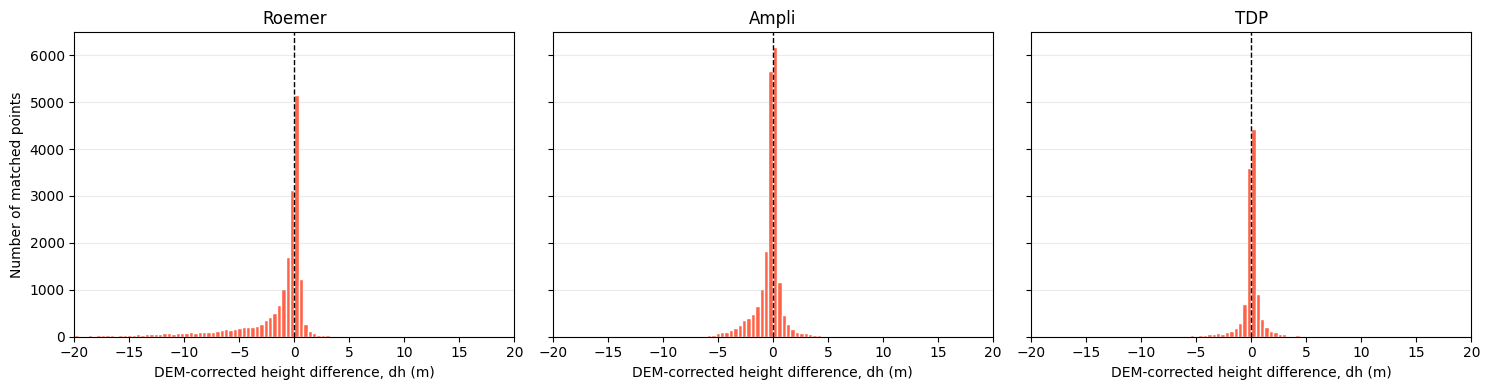

In [100]:
import numpy as np
import matplotlib.pyplot as plt

datasets = [("Roemer", roemer["dh"]), ("Ampli", ampli["dh"]), ("TDP", tdp["dh"])]

# Use identical bins and limits for a fair comparison.
plot_limit = 20  # metres
bins = np.linspace(-plot_limit, plot_limit, 101)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)

for ax, (name, values) in zip(axes, datasets):
    dh = np.asarray(values).ravel()
    dh = dh[np.isfinite(dh)]

    ax.hist(dh, bins=bins, color="tomato", edgecolor="white")
    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.set(
        title=f"{name}",
        xlabel="DEM-corrected height difference, dh (m)",
        xlim=(-plot_limit, plot_limit),
    )
    ax.grid(axis="y", alpha=0.25)

axes[0].set_ylabel("Number of matched points")
fig.tight_layout()
plt.show()

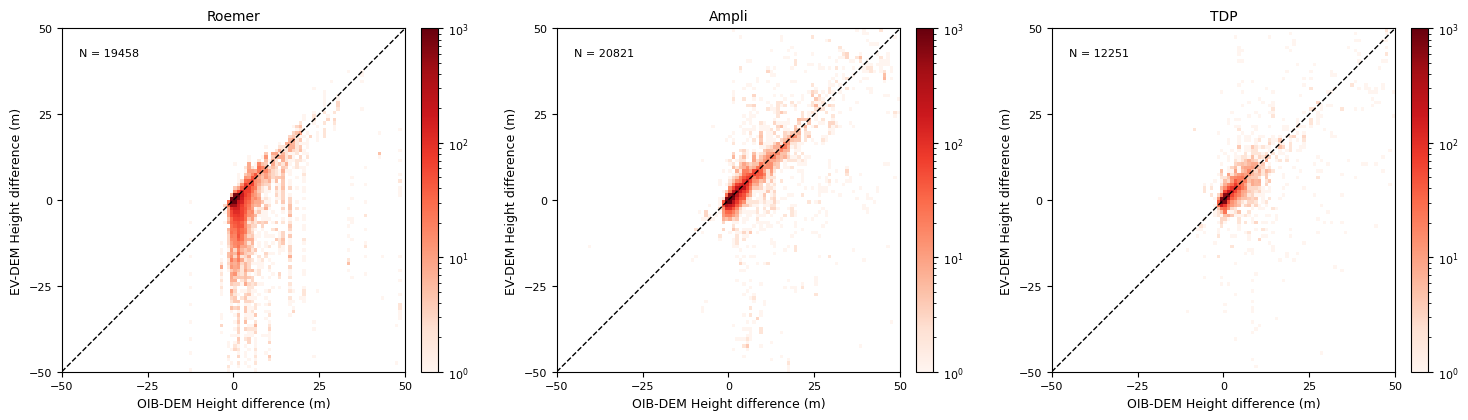

In [101]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from cpom.dems.dems import Dem

dem = Dem("arcticdem_100m_greenland_v4.1")  # must be the same DEM passed to --dem in the validation run
lim = 50          # metres
bin_size = 1      # metres per histogram cell
norm = LogNorm(vmin=1, vmax=1e3)  # same colour scale on every panel, as in the report
edges = np.arange(-lim, lim + bin_size, bin_size)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

for ax, (name, d) in zip(axes, [("Roemer", roemer), ("Ampli", ampli), ("TDP", tdp)]):
    dem_h = dem.interp_dem(np.asarray(d["x"], float), np.asarray(d["y"], float))  # DEM at product location
    reference_dem_h = dem.interp_dem(
        np.asarray(d["reference_x"], float), np.asarray(d["reference_y"], float)
    )  # DEM at OIB location
    dh_dem_elev = dem_h - reference_dem_h

    x = np.asarray(d["reference_h"], float) - reference_dem_h  # OIB - DEM
    y = np.asarray(d["h"], float) - dem_h                      # ENV - DEM

    ok = np.isfinite(x) & np.isfinite(y) & (np.abs(x) <= lim) & (np.abs(y) <= lim)

    counts, _, _ = np.histogram2d(x[ok], y[ok], bins=[edges, edges])
    counts = np.ma.masked_less(counts, 1)  # empty cells stay white
    mesh = ax.pcolormesh(edges, edges, counts.T, cmap="Reds", norm=norm)
    cbar = fig.colorbar(mesh, ax=ax, fraction=0.046, pad=0.04)
    cbar.ax.tick_params(labelsize=8)

    ax.plot([-lim, lim], [-lim, lim], "k--", lw=1)  # 1:1 line
    ax.text(0.05, 0.92, f"N = {ok.sum()}", transform=ax.transAxes, fontsize=8)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("OIB-DEM Height difference (m)", fontsize=9)
    ax.set_ylabel("EV-DEM Height difference (m)", fontsize=9)
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), aspect="equal")
    ticks = np.arange(-lim, lim + 1, 25)
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.tick_params(labelsize=8)

fig.tight_layout()
plt.show()

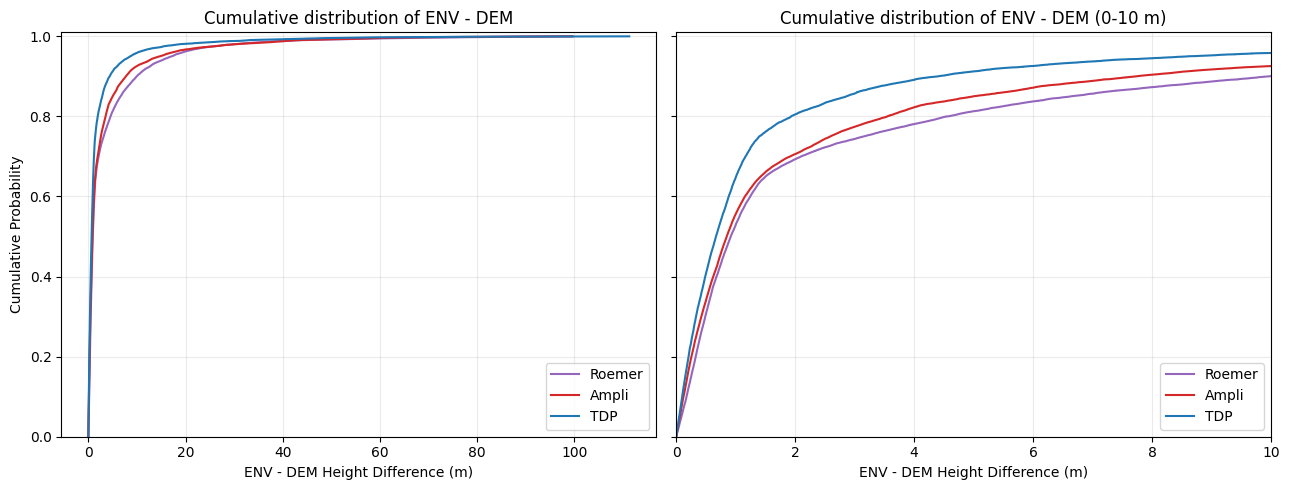

In [136]:
colours = {"Roemer": "tab:purple", "Ampli": "tab:red", "TDP": "tab:blue"}

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for name, d in [("Roemer", roemer), ("Ampli", ampli), ("TDP", tdp)]:
    dem_h = dem.interp_dem(np.asarray(d["x"], float), np.asarray(d["y"], float))
    abs_diff = np.abs(np.asarray(d["h"], float) - dem_h)  # |product - DEM|
    abs_diff = np.sort(abs_diff[np.isfinite(abs_diff)])
    if abs_diff.size == 0:
        continue
    cdf = np.arange(1, abs_diff.size + 1) / abs_diff.size
    for ax in axes:
        ax.plot(abs_diff, cdf, color=colours[name], label=name)

axes[0].set(title="Cumulative distribution of ENV - DEM")
axes[1].set(title="Cumulative distribution of ENV - DEM (0-10 m)", xlim=(0, 10))

for ax in axes:
    ax.set(xlabel="ENV - DEM Height Difference (m)", ylim=(0, 1.01))
    ax.grid(which="both", alpha=0.25)
    ax.legend(loc="lower right")
axes[0].set_ylabel("Cumulative Probability")

fig.tight_layout()
plt.show()

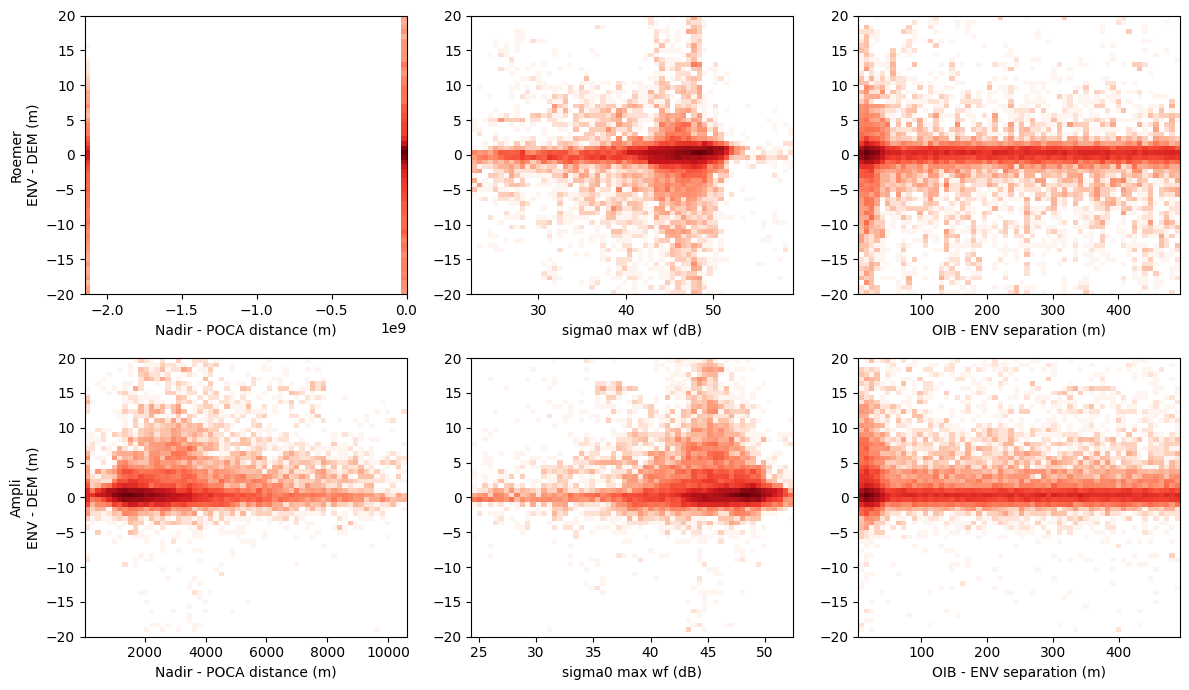

In [127]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.stats import binned_statistic, spearmanr

lim = 20  # metres, |ENV - DEM| plotted
products = [("Roemer", roemer, "roemer"), ("Ampli", ampli, "ampli")]
params = [
    ("distance_nadir_poca_{}", "Nadir - POCA distance (m)"),
    ("sigma0_max_wf", "sigma0 max wf (dB)"),
    ("sep_dist", "OIB - ENV separation (m)"),
]

fig, axes = plt.subplots(len(products), len(params), figsize=(12, 7), squeeze=False)

for row, (name, d, suffix) in enumerate(products):
    diff = np.asarray(d["h"], float) - dem.interp_dem(d["x"], d["y"])  # ENV - DEM

    for col, (key, xlabel) in enumerate(params):
        ax = axes[row, col]
        p = np.asarray(d[key.format(suffix)], float)
        ok = np.isfinite(p) & np.isfinite(diff) & (np.abs(diff) <= lim)
        p, y = p[ok], diff[ok]
        lo, hi = np.percentile(p, [1, 99])  # ignore extreme x values

        # Point density
        ax.hist2d(p, y, bins=60, range=[[lo, hi], [-lim, lim]], cmap="Reds", norm=LogNorm(), cmin=1)

        # Median trend (only bins with at least 20 points)
        med, edges, _ = binned_statistic(p, y, "median", bins=15, range=(lo, hi))
        count, _, _ = binned_statistic(p, y, "count", bins=15, range=(lo, hi))
        med[count < 20] = np.nan
        # ax.plot(0.5 * (edges[:-1] + edges[1:]), med, "k-", lw=1.5)

        # ax.axhline(0, color="k", ls="--", lw=0.8)
        # ax.set_title(f"ρ = {spearmanr(p, y)[0]:.2f}, N = {len(p):,}", fontsize=9)
        ax.set_xlabel(xlabel)
        if col == 0:
            ax.set_ylabel(f"{name}\nENV - DEM (m)")

fig.tight_layout()
plt.show()

In [124]:
# Summary statistics of the height difference dh (ENV - OIB, DEM slope-corrected, from the npz)
import numpy as np
import pandas as pd

max_abs_dh = 50  # metres; also report stats with |dh| <= this to show the effect of outliers


def dh_stats(dh):
    dh = np.asarray(dh, float)
    dh = dh[np.isfinite(dh)]
    median = np.median(dh)
    return {
        "Mean absolute height difference (m)": np.mean(np.abs(dh)),
        "Mean height difference (m)": np.mean(dh),
        "Median absolute deviation of height difference (m)": np.median(np.abs(dh - median)),
        "Median height difference (m)": median,
        "Number of comparisons": len(dh),
    }


rows = {}
for name, d in [("Roemer", roemer), ("Ampli", ampli), ("TDP", tdp)]:
    dh = np.asarray(d["dh"], float)
    rows[f"{name} (all)"] = dh_stats(dh)
    # rows[f"{name} (|dh| <= {max_abs_dh} m)"] = dh_stats(dh[np.abs(dh) <= max_abs_dh])

stats = pd.DataFrame(rows)
stats.round(3)

,Roemer (all),Ampli (all),TDP (all)
Mean absolute height difference (m),3.940,1.823,1.392
Mean height difference (m),-3.615,-0.626,-0.294
Median absolute deviation of height difference (m),0.671,0.309,0.241
Median height difference (m),-0.343,-0.060,0.027
Number of comparisons,19610.000,20998.000,12316.000


# Compare to cycle 78 

In [119]:

roemer78 = np.load("/home/willisc3/luna/CPOM/willisc3/Validation/env_roemer_vs_ilatm2_500_30_nearest_v2_78/20090406_20090511/p2p_diffs_greenland_is.npz")
ampli78 = np.load("/home/willisc3/luna/CPOM/willisc3/Validation/env_ampli_vs_ilatm2_500_30_nearest_v2_78/20090406_20090511/p2p_diffs_greenland_is.npz")
tdp78 = np.load("/home/willisc3/luna/CPOM/willisc3/Validation/env_tdp_vs_ilatm2_500_30_nearest_v2_78/20090406_20090511/p2p_diffs_greenland_is.npz")

In [116]:
tdp78['seperation_distance']

array([359.04361061,   7.95087205, 194.43578823, ..., 220.53216765,
       337.65397246, 176.47129348], shape=(4944,))

-------------------------------------------------------------
Background: basic_land
alpha= 1.0
Loading basic_land background
-------------------------------------------------------------
loading data set 0: Roemer
-------------------------------------------------------------
Background: basic_land
alpha= 1.0
Loading basic_land background
-------------------------------------------------------------


/home/willisc3/cpom_software2/src/cpom/areas/area_plot.py:1768: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(tick_labels)


drawing coastline for main map..
Adding map scale bar
Scalebar location latlon == x,y -35 60 577060.7250919531 -3272673.999029407
Scalebar width 400
Saving plot to /tmp/roemer_compare_to_icebridge.png at 85 dpi
-------------------------------------------------------------
Background: basic_land
alpha= 1.0
Loading basic_land background
-------------------------------------------------------------
loading data set 0: Ampli
-------------------------------------------------------------
Background: basic_land
alpha= 1.0
Loading basic_land background
-------------------------------------------------------------


/home/willisc3/cpom_software2/src/cpom/areas/area_plot.py:1768: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(tick_labels)


drawing coastline for main map..
Adding map scale bar
Scalebar location latlon == x,y -35 60 577060.7250919531 -3272673.999029407
Scalebar width 400
Saving plot to /tmp/ampli_compare_to_icebridge.png at 85 dpi
-------------------------------------------------------------
Background: basic_land
alpha= 1.0
Loading basic_land background
-------------------------------------------------------------
loading data set 0: TDP
-------------------------------------------------------------
Background: basic_land
alpha= 1.0
Loading basic_land background
-------------------------------------------------------------


/home/willisc3/cpom_software2/src/cpom/areas/area_plot.py:1768: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(tick_labels)


drawing coastline for main map..
Adding map scale bar
Scalebar location latlon == x,y -35 60 577060.7250919531 -3272673.999029407
Scalebar width 400
Saving plot to /tmp/tdp_compare_to_icebridge.png at 85 dpi


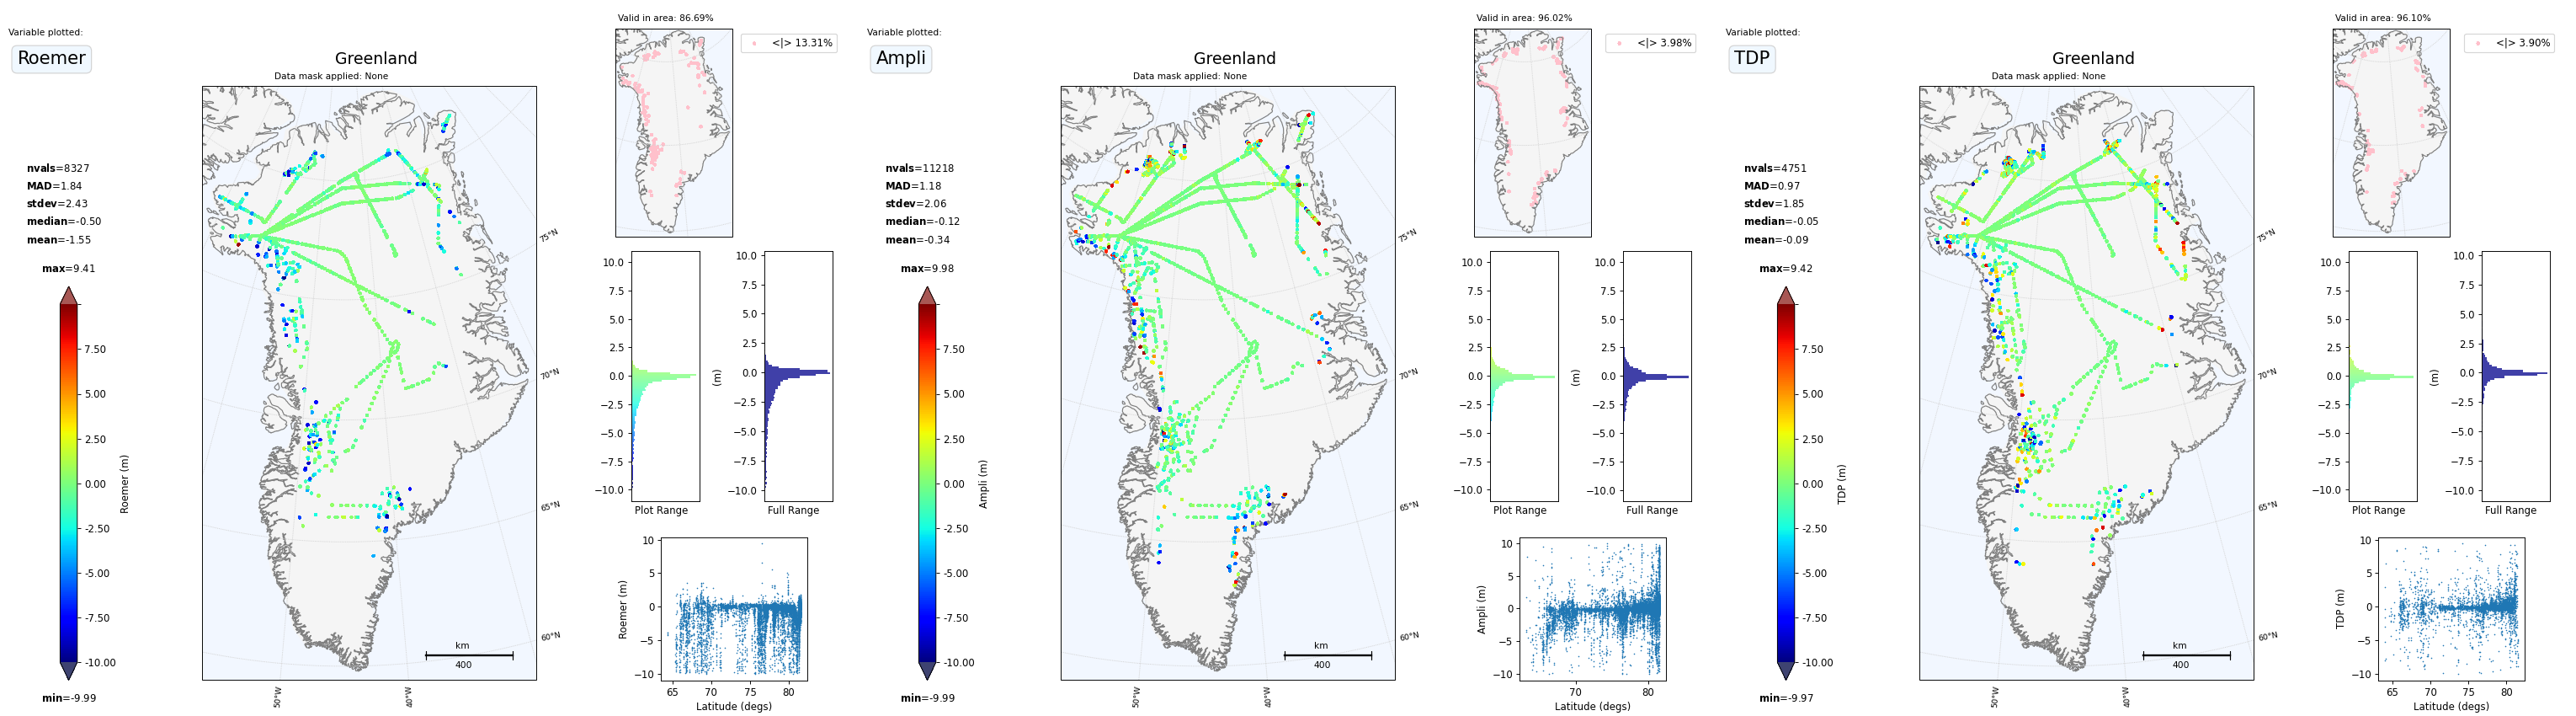

In [117]:
import os
import matplotlib.pyplot as plt
from PIL import Image

# example datasets
datasets = {
    "Roemer compare to icebridge": {
        "lats": roemer78["reference_lats"],
        "lons": roemer78["reference_lons"],
        "vals": roemer78["dh"],
        "name": "Roemer",
        "valid_range": (-10, 10),
        "units": "m",
        "cmap_name": "jet",   # better than coolwarm for zero-centered anomaly plots
        "min_plot_range": -10,
        "max_plot_range": 10,
    },
    "Ampli compare to icebridge": {
        "lats": ampli78["reference_lats"],
        "lons": ampli78["reference_lons"],
        "vals": ampli78["dh"],
        "name": "Ampli",
        "valid_range": (-10, 10),
        "units": "m",
        "cmap_name": "jet",
        "min_plot_range": -10,
        "max_plot_range": 10,
    },
    "TDP compare to icebridge": {
        "lats": tdp78["reference_lats"],
        "lons": tdp78["reference_lons"],
        "vals": tdp78["dh"],
        "name": "TDP",
        "valid_range": (-10, 10),
        "units": "m",
        "cmap_name": "jet",
        "min_plot_range": -10,
        "max_plot_range": 10,
    },
}

tmp_files = []

for title, ds in datasets.items():
    out = f"/tmp/{title.lower().replace(' ', '_')}.png"
    Polarplot("greenland").plot_points(ds, output_file=out)
    tmp_files.append(out)

# load and combine
imgs = [Image.open(p).convert("RGB") for p in tmp_files]

max_h = max(img.height for img in imgs)
total_w = sum(img.width for img in imgs)

canvas = Image.new("RGB", (total_w, max_h), "white")
x = 0
for img in imgs:
    canvas.paste(img, (x, 0))
    x += img.width

canvas

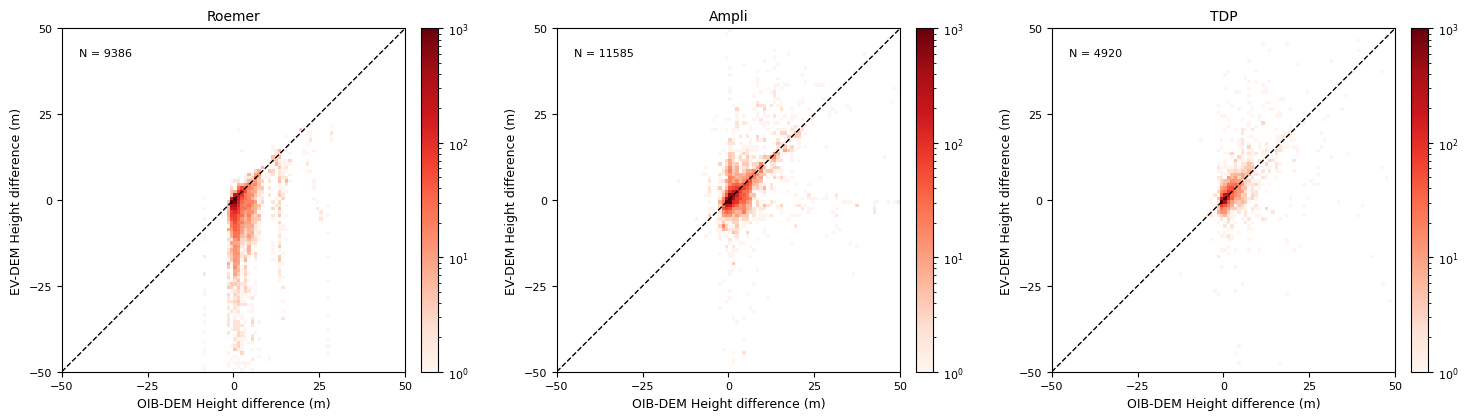

In [107]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from cpom.dems.dems import Dem

dem = Dem("arcticdem_100m_greenland_v4.1")  # must be the same DEM passed to --dem in the validation run
lim = 50          # metres
bin_size = 1      # metres per histogram cell
norm = LogNorm(vmin=1, vmax=1e3)  # same colour scale on every panel, as in the report
edges = np.arange(-lim, lim + bin_size, bin_size)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

for ax, (name, d) in zip(axes, [("Roemer",  roemer78), ("Ampli", ampli78), ("TDP", tdp78)]):
    dem_h = dem.interp_dem(np.asarray(d["x"], float), np.asarray(d["y"], float))  # DEM at product location
    reference_dem_h = dem.interp_dem(
        np.asarray(d["reference_x"], float), np.asarray(d["reference_y"], float)
    )  # DEM at OIB location
    dh_dem_elev = dem_h - reference_dem_h

    x = np.asarray(d["reference_h"], float) - reference_dem_h  # OIB - DEM
    y = np.asarray(d["h"], float) - dem_h                      # ENV - DEM

    ok = np.isfinite(x) & np.isfinite(y) & (np.abs(x) <= lim) & (np.abs(y) <= lim)

    counts, _, _ = np.histogram2d(x[ok], y[ok], bins=[edges, edges])
    counts = np.ma.masked_less(counts, 1)  # empty cells stay white
    mesh = ax.pcolormesh(edges, edges, counts.T, cmap="Reds", norm=norm)
    cbar = fig.colorbar(mesh, ax=ax, fraction=0.046, pad=0.04)
    cbar.ax.tick_params(labelsize=8)

    ax.plot([-lim, lim], [-lim, lim], "k--", lw=1)  # 1:1 line
    ax.text(0.05, 0.92, f"N = {ok.sum()}", transform=ax.transAxes, fontsize=8)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("OIB-DEM Height difference (m)", fontsize=9)
    ax.set_ylabel("EV-DEM Height difference (m)", fontsize=9)
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), aspect="equal")
    ticks = np.arange(-lim, lim + 1, 25)
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.tick_params(labelsize=8)

fig.tight_layout()
plt.show()

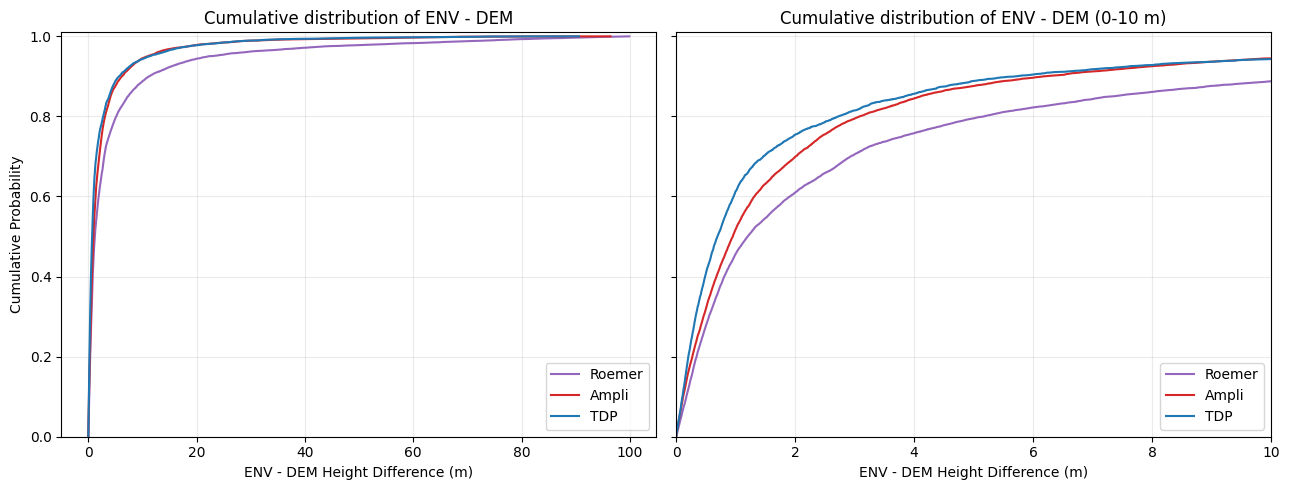

In [135]:
colours = {"Roemer": "tab:purple", "Ampli": "tab:red", "TDP": "tab:blue"}

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for name, d in [("Roemer", roemer78), ("Ampli", ampli78), ("TDP", tdp78)]:
    dem_h = dem.interp_dem(np.asarray(d["x"], float), np.asarray(d["y"], float))
    abs_diff = np.abs(np.asarray(d["h"], float) - dem_h)  # |product - DEM|
    abs_diff = np.sort(abs_diff[np.isfinite(abs_diff)])
    if abs_diff.size == 0:
        continue
    cdf = np.arange(1, abs_diff.size + 1) / abs_diff.size
    for ax in axes:
        ax.plot(abs_diff, cdf, color=colours[name], label=name)

axes[0].set(title="Cumulative distribution of ENV - DEM")
axes[1].set(title="Cumulative distribution of ENV - DEM (0-10 m)", xlim=(0, 10))

for ax in axes:
    ax.set(xlabel="ENV - DEM Height Difference (m)", ylim=(0, 1.01))
    ax.grid(which="both", alpha=0.25)
    ax.legend(loc="lower right")
axes[0].set_ylabel("Cumulative Probability")

fig.tight_layout()
plt.show()

In [118]:
# Summary statistics of the height difference dh (ENV - OIB, DEM slope-corrected, from the npz)
import numpy as np
import pandas as pd

max_abs_dh = 50  # metres; also report stats with |dh| <= this to show the effect of outliers


def dh_stats(dh):
    dh = np.asarray(dh, float)
    dh = dh[np.isfinite(dh)]
    median = np.median(dh)
    return {
        "Mean absolute height difference (m)": np.mean(np.abs(dh)),
        "Mean height difference (m)": np.mean(dh),
        "Median absolute deviation of height difference (m)": np.median(np.abs(dh - median)),
        "Median height difference (m)": median,
        "Number of comparisons": int(len(dh)),
    }


rows = {}
for name, d in [("Roemer", roemer78), ("Ampli", ampli78), ("TDP", tdp78)]:
    dh = np.asarray(d["dh"], float)
    rows[f"{name}"] = dh_stats(dh)
    # rows[f"{name} (|dh| <= {max_abs_dh} m)"] = dh_stats(dh[np.abs(dh) <= max_abs_dh])

stats = pd.DataFrame(rows)
stats.round(3)
stats

,Roemer,Ampli,TDP
Mean absolute height difference (m),5.527327,2.214552,1.919067
Mean height difference (m),-5.336038,-0.507030,-0.231337
Median absolute deviation of height difference (m),1.061841,0.507090,0.344992
Median height difference (m),-0.883544,-0.125726,-0.052676
Number of comparisons,9605.000000,11683.000000,4944.000000


# Track analysis 

In [2]:
#modules
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import glob
from netCDF4 import Dataset
import pyproj
import math
import os

# import CPOM modules
from cpom.areas.area_plot import Polarplot
from cpom.areas.areas import Area # cryosphere area definitions


In [149]:
Dataset("/home/willisc3/luna/CPOM/archive/SATS/RA/ENV/L2/FDR4ALT/AMPLI_TDP/v2/supplementary_info/track_analysis/std_T0397.nc")

<class 'netCDF4.Dataset'>
root group (NETCDF4 data model, file format HDF5):
    conventions: CF-1.8
    title: Standard deviations of elevations from Thematic Data Product: Land Ice
    pass_number: 397
    publisher_url: https://earth.esa.int/eogateway
    dimensions(sizes): time(1517)
    variables(dimensions): int32 lat(time), int32 lon(time), float64 L2_elevation_std(time), float64 TDP_elevation_std(time), float64 std_diff(time), float64 std_percentage_diff(time), int32 improvement(time)
    groups: 

In [ ]:
files = '/home/willisc3/luna/CPOM/archive/SATS/RA/ENV/L2/FDR4ALT/AMPLI_TDP/v2/supplementary_info/track_analysis/*.nc'
files

#create empty dataframe to add variables to lat lon elev time
df= pd.DataFrame()
i=0
ncfiles = glob.glob(files)

#loop over each netcdf and get variables needed
for ncfile in ncfiles:
    
    #open nc file
    nc=Dataset(ncfile)
    read = lambda name: np.ma.filled(nc.variables[name][:].astype(float), np.nan)
    lat = read("lat")
    lon = read("lon")
    improv = read("improvement")
    L2_std = read("L2_elevation_std")
    TDP_std = read("TDP_elevation_std")
    std_diff = read("std_diff")
    std_perdiff = read("std_percentage_diff")
    nc.close()

    df2=pd.DataFrame({'lon':lon, 'lat':lat, 'improv':improv,'L2_std':L2_std,
                      'TDP_std':TDP_std, 'std_diff':std_diff, 'std_perdiff':std_perdiff})

    #append to dataframe
    df=pd.concat([df,df2], ignore_index=True) #output is dataframe, df, of loaded variables from netcdfs + dem elev + surface type

lats = df.lat
lons = df.lon
L2_std = df.L2_std
TDP_std= df.TDP_std
std_perdiff = df.std_perdiff
std_perdiff=np.where(std_perdiff > 0, np.nan, std_perdiff)
std_perdiff = np.absolute(std_perdiff)


-------------------------------------------------------------
Background: basic_land
alpha= 1.0
Loading basic_land background
-------------------------------------------------------------
loading data set 0: AMPLI STD


/home/willisc3/cpom_software2/src/cpom/areas/area_plot.py:1768: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(tick_labels)


drawing coastline for main map..
Adding map scale bar
Scalebar location latlon == x,y -35 60 577060.7250919531 -3272673.999029407
Scalebar width 400
Saving plot to /tmp/trio_std_percentage_difference.png at 85 dpi
-------------------------------------------------------------
Background: basic_land
alpha= 1.0
Loading basic_land background
-------------------------------------------------------------
loading data set 0: TDP STD


/home/willisc3/cpom_software2/src/cpom/areas/area_plot.py:1768: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(tick_labels)


drawing coastline for main map..
Adding map scale bar
Scalebar location latlon == x,y -35 60 577060.7250919531 -3272673.999029407
Scalebar width 400
Saving plot to /tmp/trio_std_percentage_difference.png at 85 dpi
-------------------------------------------------------------
Background: basic_land
alpha= 1.0
Loading basic_land background
-------------------------------------------------------------
loading data set 0: std percentage difference


/home/willisc3/cpom_software2/src/cpom/areas/area_plot.py:1768: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(tick_labels)


drawing coastline for main map..
Adding map scale bar
Scalebar location latlon == x,y -35 60 577060.7250919531 -3272673.999029407
Scalebar width 400
Saving plot to /tmp/trio_std_percentage_difference.png at 85 dpi


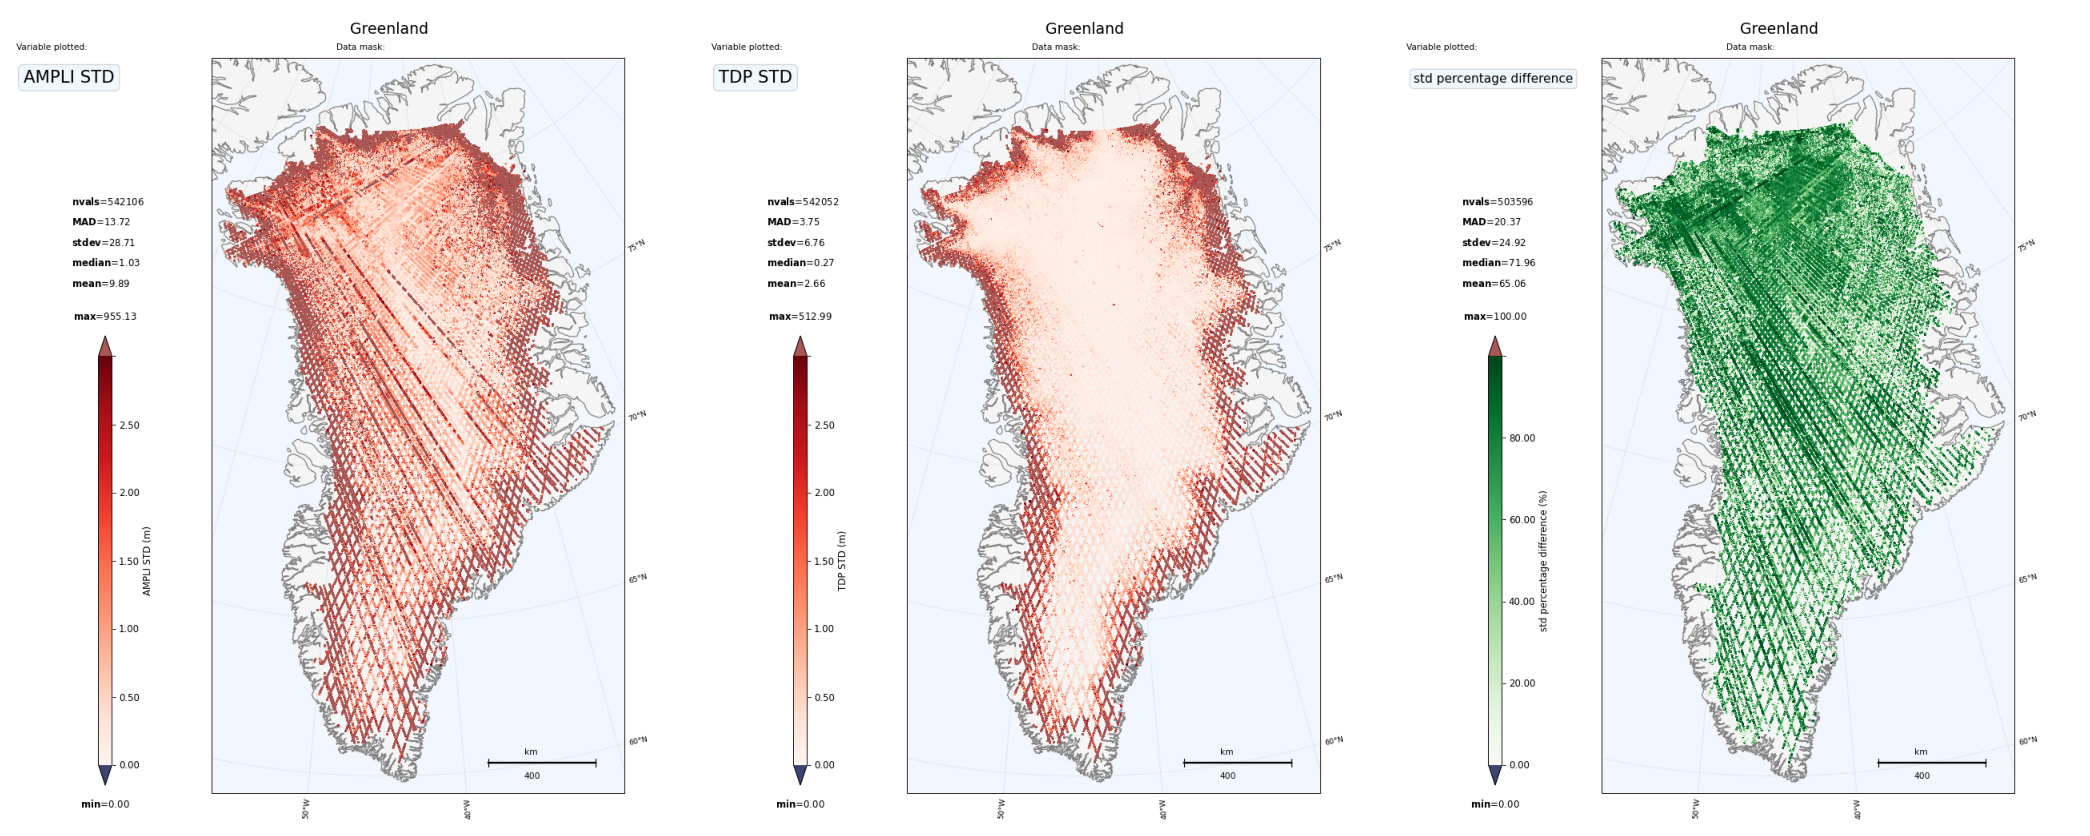

In [42]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

from cpom.areas.area_plot import Polarplot

AREA = "greenland_is"      # grounded ice sheet mask; "greenland_hs_is" adds hillshade background
data = df                  # Maddalen's std files; use df_tracks for your own results

# The df loading cell swaps lat/lon: switch them back if needed
lats, lons = data["lat"].to_numpy(float), data["lon"].to_numpy(float)
if np.nanmax(lats) > 90:
    lats, lons = lons, lats

# Remove any remaining fill values (INT32 max 2147483647) and negative stds
FILL = 1e6
L2_std[(L2_std > FILL) | (L2_std < 0)] = np.nan
TDP_std[(TDP_std > FILL) | (TDP_std < 0)] = np.nan
std_perdiff[np.abs(std_perdiff) > FILL] = np.nan

# Maddalen's files store no-data as std == 0
zero = (L2_std == 0) | (TDP_std == 0)
L2_std[zero] = TDP_std[zero] = np.nan

std_perdiff = df.std_perdiff
std_perdiff=np.where(std_perdiff > 0, np.nan, std_perdiff)
std_perdiff = np.absolute(std_perdiff)

# reduction = np.where((perdiff < 0) & ~zero, -perdiff, np.nan)  # % reduction where TDP is better

maps = [
    ("AMPLI STD",  L2_std,    "m", "Reds",   3),
    ("TDP STD", TDP_std,   "m", "Reds",   3),
    ("std percentage difference", std_perdiff, "%", "Greens", 100),
]

fig, axes = plt.subplots(1, 3, figsize=(21, 9))
for ax, (title, vals, units, cmap, vmax) in zip(axes, maps):
    # out = f"/tmp/trio_{title.replace(' ', '_')}.png"
    Polarplot(AREA).plot_points(
        {
            "name": title,
            "lats": lats,
            "lons": lons,
            "vals": vals,
            "units": units,
            "cmap_name": cmap,
            "min_plot_range": 0,
            "max_plot_range": vmax,
            "plot_size_scale_factor": 0.3,
        },
        output_file=out,
        map_only=True,  # main map only: no stats, side histograms or inset
    )
    ax.imshow(Image.open(out))
    # ax.set_title(title, loc="left", fontsize=16, fontweight="bold")
    ax.axis("off")

fig.tight_layout()
plt.show()


Setting round
-------------------------------------------------------------
Background: basic_land
alpha= 1.0
Loading basic_land background
-------------------------------------------------------------
loading data set 0: AMPLI STD
drawing coastline for main map..
Plotting Antarctic Medium coastline..


ShapefileException: Unable to open /home/willisc3/luna/CPOM/willisc3/cpom_software/resources/coastlines/Coastline_medium_res_line/Coastline_medium_res_line_WGS84.dbf or /home/willisc3/luna/CPOM/willisc3/cpom_software/resources/coastlines/Coastline_medium_res_line/Coastline_medium_res_line_WGS84.shp.

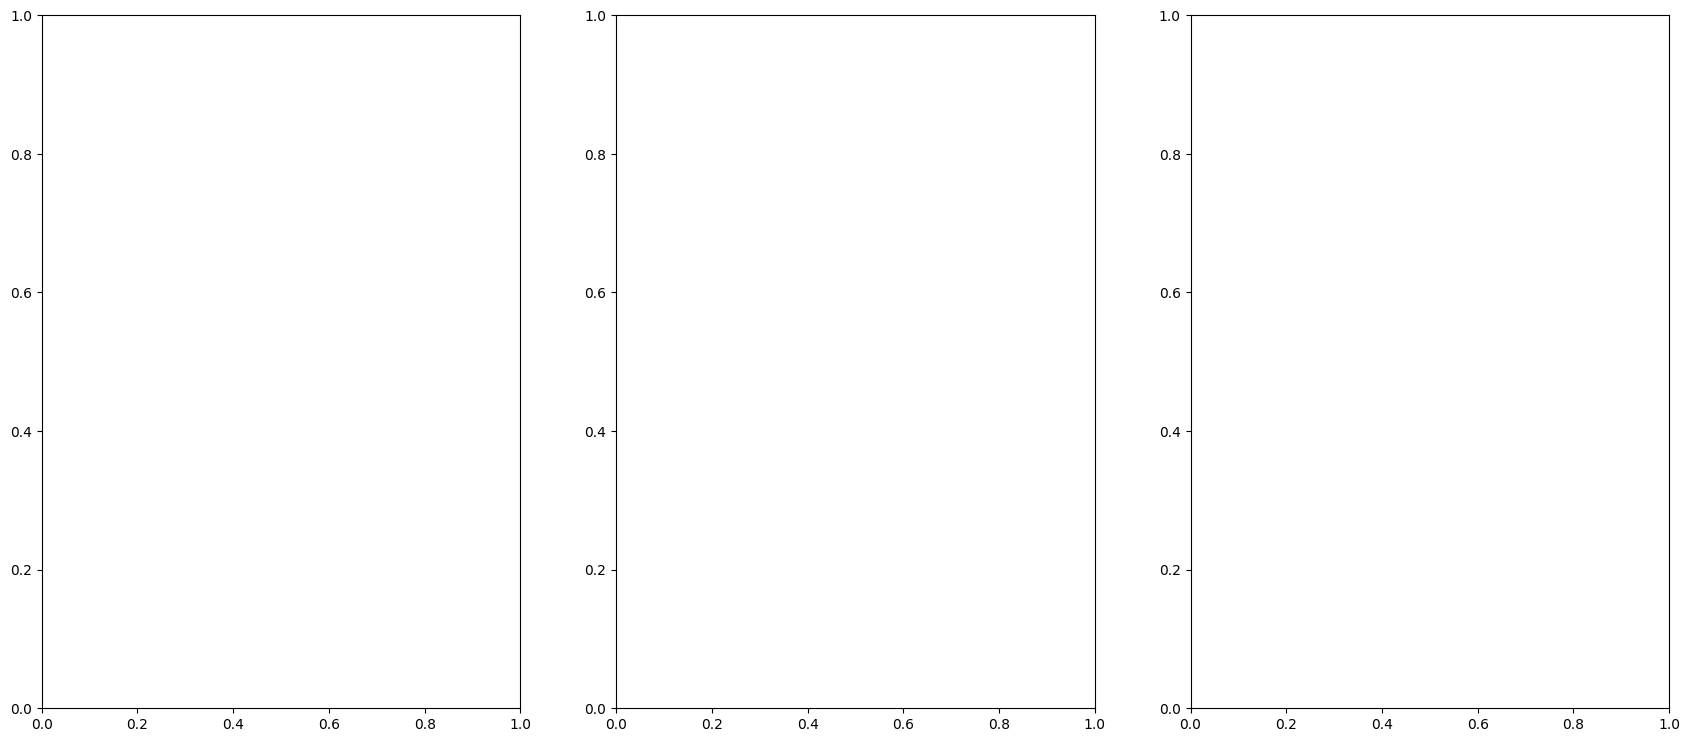

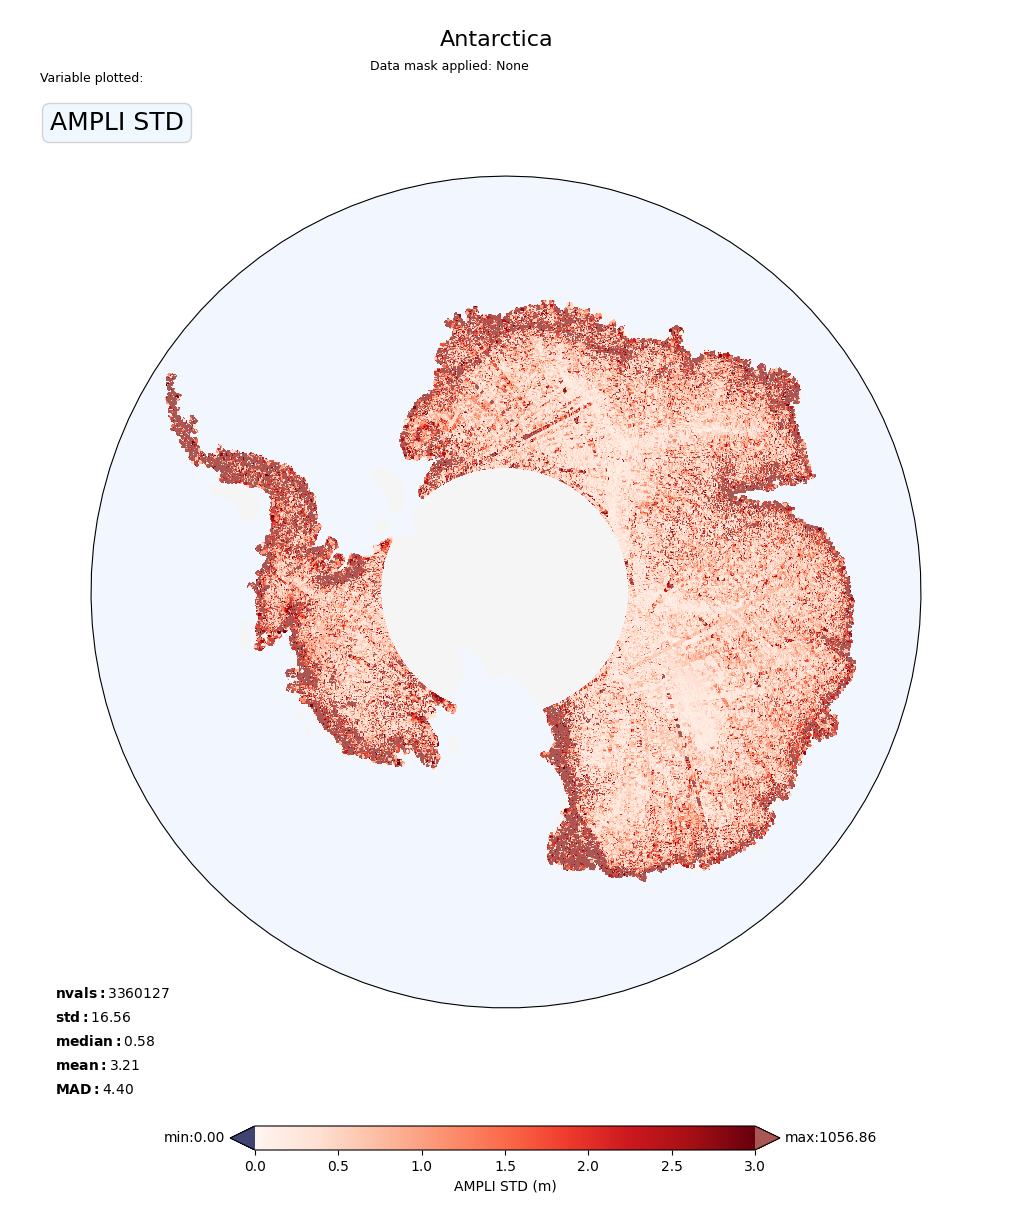

In [ ]:
files = '/home/willisc3/luna/CPOM/archive/SATS/RA/ENV/L2/FDR4ALT/AMPLI_TDP/v2/antarctica/supplementary_info/track_analysis/*.nc'
files

#create empty dataframe to add variables to lat lon elev time
df= pd.DataFrame()
i=0
ncfiles = glob.glob(files)

#loop over each netcdf and get variables needed
for ncfile in ncfiles:
    
    #open nc file
    nc=Dataset(ncfile)
    read = lambda name: np.ma.filled(nc.variables[name][:].astype(float), np.nan)
    lat = read("lat")
    lon = read("lon")
    improv = read("improvement")
    L2_std = read("L2_elevation_std")
    TDP_std = read("TDP_elevation_std")
    std_diff = read("std_diff")
    std_perdiff = read("std_percentage_diff")
    nc.close()

    df2=pd.DataFrame({'lon':lon, 'lat':lat, 'improv':improv,'L2_std':L2_std,
                      'TDP_std':TDP_std, 'std_diff':std_diff, 'std_perdiff':std_perdiff})

    #append to dataframe
    df=pd.concat([df,df2], ignore_index=True) #output is dataframe, df, of loaded variables from netcdfs + dem elev + surface type

lats = df.lat
lons = df.lon
L2_std = df.L2_std
TDP_std= df.TDP_std
std_perdiff = df.std_perdiff
std_perdiff=np.where(std_perdiff > 0, np.nan, std_perdiff)
std_perdiff = np.absolute(std_perdiff)

Setting round
-------------------------------------------------------------
Background: basic_land
alpha= 1.0
Loading basic_land background
-------------------------------------------------------------
loading data set 0: AMPLI STD
drawing coastline for main map..
Plotting Antarctic Medium coastline..
Adding map scale bar
Scalebar location latlon == x,y -179.9 -65.0 -4814.49170433531 -2758497.750633273
Scalebar width 1000
Saving plot to /tmp/trio_std_percentage_difference.png at 85 dpi
Setting round
-------------------------------------------------------------
Background: basic_land
alpha= 1.0
Loading basic_land background
-------------------------------------------------------------
loading data set 0: TDP STD
drawing coastline for main map..
Plotting Antarctic Medium coastline..
Adding map scale bar
Scalebar location latlon == x,y -179.9 -65.0 -4814.49170433531 -2758497.750633273
Scalebar width 1000
Saving plot to /tmp/trio_std_percentage_difference.png at 85 dpi
Setting round
------

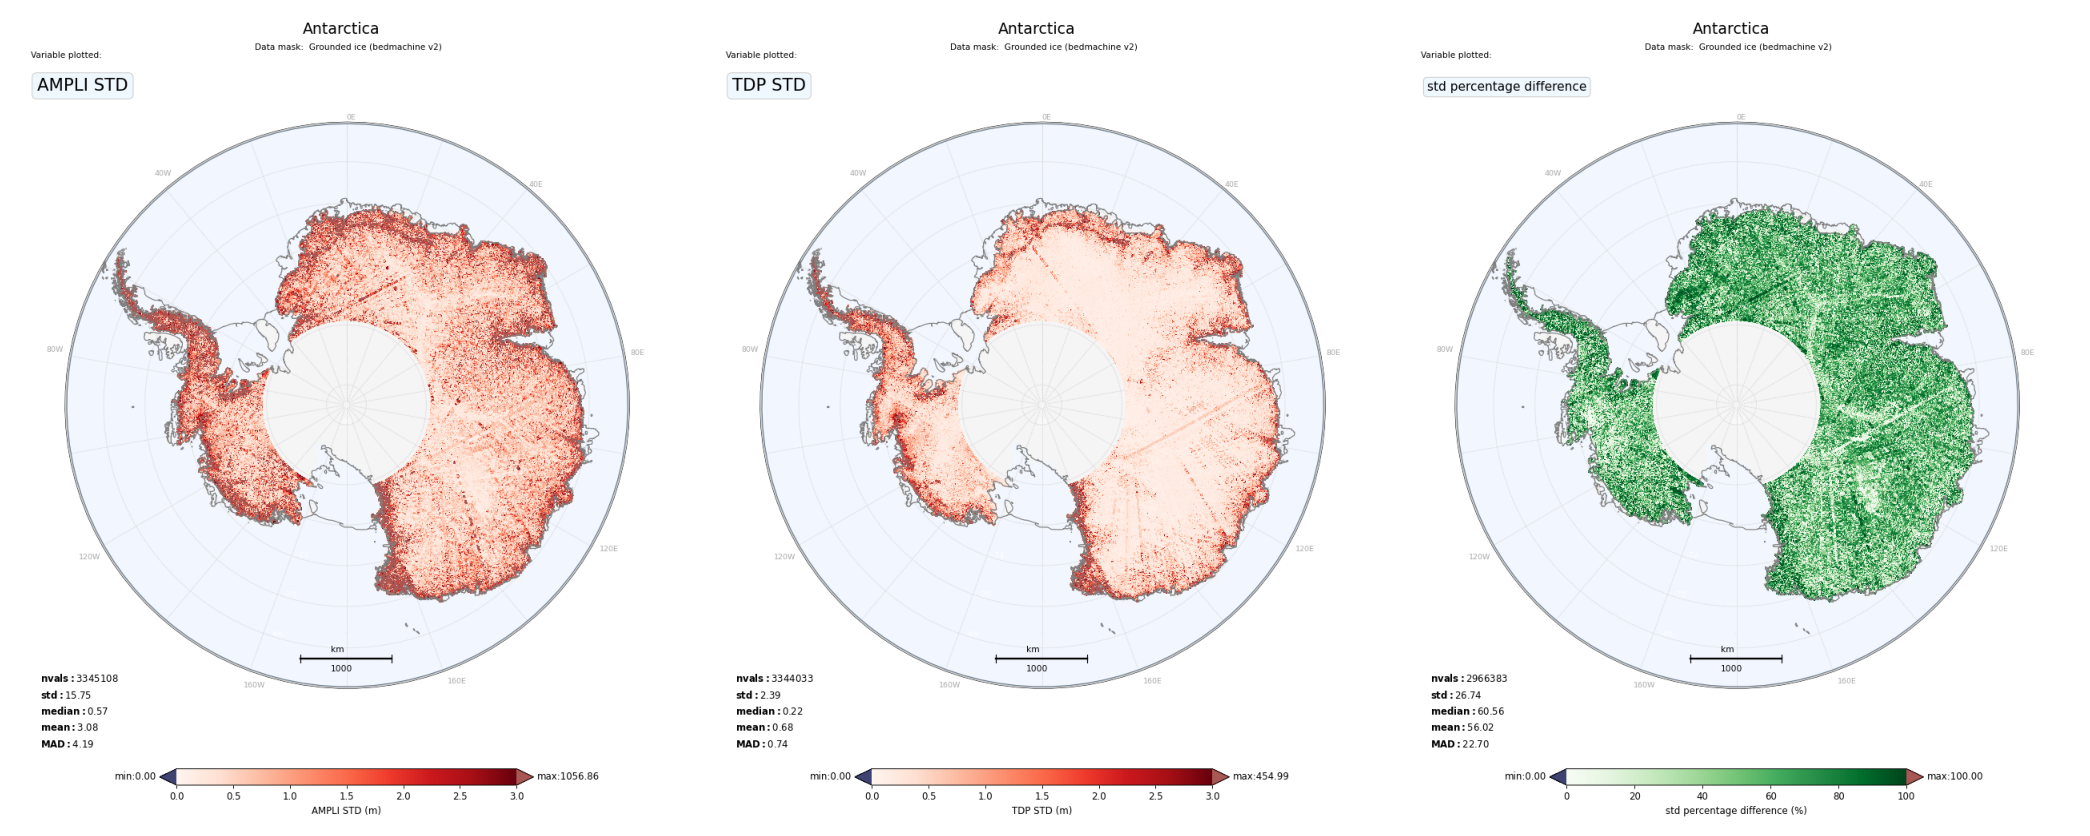

In [45]:
import os
os.environ["CPOM_SOFTWARE_DIR"] = "/home/willisc3/cpom_software2"

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

from cpom.areas.area_plot import Polarplot

AREA = "antarctica_is"      # grounded ice sheet mask; "greenland_hs_is" adds hillshade background
data = df                  # Maddalen's std files; use df_tracks for your own results

# The df loading cell swaps lat/lon: switch them back if needed
lats, lons = data["lat"].to_numpy(float), data["lon"].to_numpy(float)
if np.nanmax(lats) > 90:
    lats, lons = lons, lats

# Remove any remaining fill values (INT32 max 2147483647) and negative stds
FILL = 1e6
L2_std[(L2_std > FILL) | (L2_std < 0)] = np.nan
TDP_std[(TDP_std > FILL) | (TDP_std < 0)] = np.nan
std_perdiff[np.abs(std_perdiff) > FILL] = np.nan

# Maddalen's files store no-data as std == 0
zero = (L2_std == 0) | (TDP_std == 0)
L2_std[zero] = TDP_std[zero] = np.nan

std_perdiff = df.std_perdiff
std_perdiff=np.where(std_perdiff > 0, np.nan, std_perdiff)
std_perdiff = np.absolute(std_perdiff)

# reduction = np.where((perdiff < 0) & ~zero, -perdiff, np.nan)  # % reduction where TDP is better

maps = [
    ("AMPLI STD",  L2_std,    "m", "Reds",   3),
    ("TDP STD", TDP_std,   "m", "Reds",   3),
    ("std percentage difference", std_perdiff, "%", "Greens", 100),
]

fig, axes = plt.subplots(1, 3, figsize=(21, 9))
for ax, (title, vals, units, cmap, vmax) in zip(axes, maps):
    # out = f"/tmp/trio_{title.replace(' ', '_')}.png"
    Polarplot(AREA).plot_points(
        {
            "name": title,
            "lats": lats,
            "lons": lons,
            "vals": vals,
            "units": units,
            "cmap_name": cmap,
            "min_plot_range": 0,
            "max_plot_range": vmax,
            "plot_size_scale_factor": 0.3,
        },
        output_file=out,
        map_only=True,  # main map only: no stats, side histograms or inset
    )
    ax.imshow(Image.open(out))
    # ax.set_title(title, loc="left", fontsize=16, fontweight="bold")
    ax.axis("off")

fig.tight_layout()
plt.show()


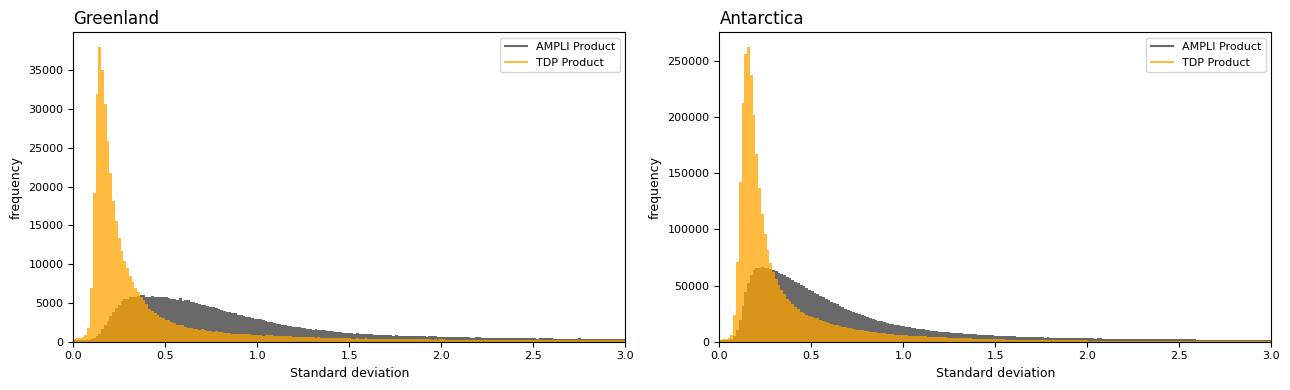

In [35]:
import glob

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from netCDF4 import Dataset

STD_DIRS = {
    "Greenland": "/home/willisc3/luna/CPOM/archive/SATS/RA/ENV/L2/FDR4ALT/AMPLI_TDP/v2/supplementary_info/track_analysis",
    "Antarctica": "/home/willisc3/luna/CPOM/archive/SATS/RA/ENV/L2/FDR4ALT/AMPLI_TDP/v2/antarctica/supplementary_info/track_analysis",
}
DROP_ZEROS = True                # remove no-data std == 0
BINS = np.linspace(0, 3, 200)    # 299 bins, ~0.01 m wide


def load_std(directory):
    """L2 and TDP std from every std_T*.nc file in a directory."""
    l2, tdp = [], []
    for f in sorted(glob.glob(f"{directory}/std_T*.nc")):
        with Dataset(f) as nc:
            l2.append(np.ma.filled(nc["L2_elevation_std"][:].astype(float), np.nan))
            tdp.append(np.ma.filled(nc["TDP_elevation_std"][:].astype(float), np.nan))
    return np.concatenate(l2), np.concatenate(tdp)


def plot_std_hist(ax, l2, tdp, title):
    """Overlaid L2 / TDP std histograms, styled like the original report figure."""
    l2, tdp = np.asarray(l2, float), np.asarray(tdp, float)
    if DROP_ZEROS:
        zero = (l2 == 0) | (tdp == 0)
        l2, tdp = l2[~zero], tdp[~zero]
    ax.hist(l2[np.isfinite(l2)], bins=BINS, histtype="stepfilled", color="dimgrey")
    ax.hist(tdp[np.isfinite(tdp)], bins=BINS, histtype="stepfilled", color="orange", alpha=0.75)
    ax.set_xlim(0, 3)
    ax.set_xlabel("Standard deviation", fontsize=9)
    ax.set_ylabel("frequency", fontsize=9)
    ax.tick_params(labelsize=8)
    ax.set_title(title, loc="left")
    ax.legend(
        handles=[
            Line2D([0], [0], color="dimgrey", label="AMPLI Product"),
            Line2D([0], [0], color="orange", alpha=0.75, label="TDP Product"),
        ],
        fontsize=8,
    )


fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (region, directory) in zip(axes, STD_DIRS.items()):
    l2, tdp = load_std(directory)
    plot_std_hist(ax, l2, tdp, region)
fig.tight_layout()
plt.show()
